# 15 — open-appsec: real təmiz veb trafikində yanlış bloklama

**Sual:** detektorlar real saytların təmiz HTTP trafikində nə qədər yanlış bloklama verir?

- Məlumat: open-appsec WAF Comparison Project (`openappsec/waf-comparison-project`, Apache 2.0). Repoda `Data` qovluğu yoxdur;
  `config.py` təmiz dəsti `legitimate.zip`-dən yükləyir: 692 brauzer sessiyasında (open-appsec `legitimate.zip`, hər sessiya bir JSON faylı) yazılmış **1 040 242 HTTP sorğusu**, hamısı təmiz.
  Yalnız bu (legitimate) dəst istifadə olunur.
- Modellərimiz tək parametr dəyəri üzərində öyrədilib. Ona görə hər sorğudan middleware-in (`middleware/src/sqliGuard.js`) yoxlayacağı dəyərlər çıxarılır
  (`src/openappsec.py`): URL query (Express kimi bir dəfə decode), body — `application/json` (bütün sətir yarpaqları), `x-www-form-urlencoded`, `multipart/form-data` (fayl olmayan sahələr);
  digər body növləri (text/plain, protobuf, binar beacon-lar, CSP hesabatları) Express parserləri tərəfindən oxunmur və yoxlanılmır. Açarlar yox, yalnız dəyərlər; 4 096 simvoldan uzun dəyərlər kəsilir (middleware standartı).
- Detektorlar (seed 42–46): TF-IDF LR / SVM / RF / NB baza, LR + normallaşdırma, LR + normallaşdırma + augmentation (12/14 ilə eyni modellər), char-CNN baza və normallaşdırma (13 ilə eyni),
  qara siyahı ×2 və libinjection (deterministik, seed-dən asılı deyil).
- **Dəyər səviyyəsində FPR:** bloklanan unikal dəyərlərin payı (və tezliklə çəkili pay).
  **Sorğu səviyyəsində FPR:** sorğunun dəyərlərindən biri bloklanırsa, sorğu bloklanmış sayılır; məxrəc — ən azı bir dəyəri olan sorğular (dəyərsiz sorğu bloklana bilməz; bütün sorğulara görə pay da verilir).

In [1]:
import sys, time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import openappsec as oa
from charcnn import CONFIGS as CNN_CONFIGS, get_cnn
from detectors import BL_INPUT, BL_SEARCH, LIBINJ, train_all
from experiments import load_clean, make_split

RES, FIG = ROOT / "results", ROOT / "figures" / "paper"
FIG.mkdir(parents=True, exist_ok=True)
SEEDS = [42, 43, 44, 45, 46]
DEPLOYED = "LR + norm. + augmentation"   # middleware modeli
clean = load_clean()
oa.fetch()
requests, values = oa.load()
print(len(requests), "sorğu,", len(values), "dəyər")

1040242 sorğu, 9520543 dəyər


## 1. Dəyərlərin çıxarılması

In [2]:
codes, uniq = pd.factorize(values.value)
values["code"] = codes
n_req = len(requests)
has_val = requests.n_values.to_numpy() > 0
summary = pd.Series({
    "sorğular": n_req, "brauzer sessiyaları (JSON faylları)": requests.site.nunique(),
    "ən azı bir dəyəri olan sorğular": int(has_val.sum()),
    "dəyərlər (hamısı)": len(values), "unikal dəyərlər": len(uniq),
    "boş dəyərlər (hamısı içində, %)": round(100 * (values.value == "").mean(), 2),
    "4096-dan uzun (kəsilmiş) dəyərlər": int(values.truncated.sum()),
    **{f"dəyərlər: {k}": int(v) for k, v in values.source.value_counts().items()},
    "median dəyər uzunluğu": float(pd.Series(uniq).str.len().median()),
})
summary.to_csv(RES / "15_extraction_summary.csv", header=["value"])
display(summary.to_frame("dəyər"))
requests.content_type.value_counts().head(15)

,dəyər
sorğular,1040242.0
brauzer sessiyaları (JSON faylları),692.0
ən azı bir dəyəri olan sorğular,657160.0
dəyərlər (hamısı),9520543.0
unikal dəyərlər,833477.0
"boş dəyərlər (hamısı içində, %)",4.0
4096-dan uzun (kəsilmiş) dəyərlər,6968.0
dəyərlər: query,5039854.0
dəyərlər: body_json,4220419.0
dəyərlər: body_form,236765.0


content_type
                                      738865
application/json                      132839
text/plain                            109047
application/x-www-form-urlencoded      46382
multipart/form-data                     5113
application/csp-report                  1576
application/vnd.chrome.uma              1024
application/x-protobuf                   875
application/json, application/json       850
message/ohttp-req                        847
application/json+protobuf                661
application/vnd.kafka.json.v2+json       312
application/reports+json                 247
application/octet-stream                 200
application/x-protobuffer                195
Name: count, dtype: int64

## 2. FPR — 5 seed

In [3]:
U = pd.Series(uniq)
occ = np.bincount(codes, minlength=len(uniq))           # hər unikal dəyərin tezliyi
req_of_val = values.req_id.to_numpy()

PRED_CACHE = ROOT / "models" / "15_preds"          # yarımçıq kəsilmədə hesablanmış proqnozlar itməsin (git-də yox)
PRED_CACHE.mkdir(parents=True, exist_ok=True)

def chunked(det, xs, n=50_000, key=None):
    f = PRED_CACHE / f"{key}.npy" if key else None
    if f is not None and f.exists():
        p = np.load(f)
        if len(p) == len(xs):
            return p
    p = np.concatenate([np.asarray(det(xs[i:i + n])) for i in range(0, len(xs), n)]).astype(np.int8)
    if f is not None:
        np.save(f, p)
    return p

def slug(name):
    return "".join(ch if ch.isalnum() else "_" for ch in name)

def fpr_rows(name, seed, pred_u):
    pred_occ = pred_u[codes]
    blocked_req = np.bincount(req_of_val, weights=pred_occ, minlength=n_req) > 0
    return [{"seed": seed, "detector": name, "metric": m, "value": v} for m, v in (
        ("fpr_value_unique", pred_u.mean()),
        ("fpr_value_weighted", pred_occ.mean()),
        ("fpr_request", blocked_req[has_val].mean()),
        ("fpr_request_all", blocked_req.mean()),
        ("blocked_requests", blocked_req.sum()))]

rows, preds42 = [], {}
xs = U.tolist()
for name, det in (("Qara siyahı (sanitizeInput)", BL_INPUT), ("Qara siyahı (sanitizeSearch)", BL_SEARCH),
                  ("libinjection 4.0.1", LIBINJ)):
    t0 = time.perf_counter()
    p = chunked(det, xs, key=f"{slug(name)}_det")
    preds42[name] = p
    for s in SEEDS:                                     # deterministik: hər seed üçün eyni
        rows += fpr_rows(name, s, p)
    print(f"{name:30s} {time.perf_counter() - t0:.0f} s")

for s in SEEDS:
    t0 = time.perf_counter()
    train, val, _ = make_split(clean, s)
    dets = {k: m.predict for k, m in train_all(s, train, val).items()}
    for cfg in CNN_CONFIGS:
        dets[cfg] = get_cnn(cfg, s, train, val).predict
    for name, det in dets.items():
        p = chunked(det, xs, key=f"{slug(name)}_{s}")
        rows += fpr_rows(name, s, p)
        if s == 42:
            preds42[name] = p
    print(f"seed {s}: {time.perf_counter() - t0:.0f} s")

raw = pd.DataFrame(rows)
raw.to_csv(RES / "15_fpr_raw.csv", index=False)

Qara siyahı (sanitizeInput)    27 s


Qara siyahı (sanitizeSearch)   19 s


libinjection 4.0.1             5 s


seed 42: 2669 s


seed 43: 2487 s


seed 44: 2264 s


seed 45: 2287 s


seed 46: 2489 s


In [4]:
ORDER = ["LR baza", "SVM baza", "RF baza", "NB baza", "LR + normallaşdırma", "LR + norm. + augmentation",
         "CNN baza", "CNN + normallaşdırma", "Qara siyahı (sanitizeInput)", "Qara siyahı (sanitizeSearch)", "libinjection 4.0.1"]
pct = raw[raw.metric != "blocked_requests"]
a = pct.groupby(["detector", "metric"]).value.agg(["mean", "std"]) * 100
a.round(4).to_csv(RES / "15_fpr_mean_std.csv")
pm = lambda d: d["mean"].map("{:.3f}".format) + " ± " + d["std"].map("{:.3f}".format)
table = pm(a).unstack("metric").loc[ORDER, ["fpr_value_unique", "fpr_value_weighted", "fpr_request", "fpr_request_all"]]
blocked = raw[raw.metric == "blocked_requests"].groupby("detector").value.mean().loc[ORDER].round(0).astype(int)
table["bloklanan sorğu (orta)"] = blocked
table.to_csv(RES / "15_fpr_table.csv")
table

metric,fpr_value_unique,fpr_value_weighted,fpr_request,fpr_request_all,bloklanan sorğu (orta)
detector,,,,,
LR baza,0.871 ± 0.133,3.823 ± 2.523,16.957 ± 8.798,10.712 ± 5.558,111433
SVM baza,0.993 ± 0.191,3.006 ± 2.471,14.287 ± 8.525,9.026 ± 5.386,93890
RF baza,0.348 ± 0.009,9.849 ± 3.139,34.529 ± 5.315,21.814 ± 3.358,226913
NB baza,37.712 ± 0.638,33.531 ± 0.392,73.043 ± 0.541,46.144 ± 0.341,480013
LR + normallaşdırma,0.997 ± 0.269,5.584 ± 3.313,22.720 ± 9.455,14.353 ± 5.973,149310
LR + norm. + augmentation,1.242 ± 0.174,4.885 ± 1.968,22.323 ± 7.385,14.102 ± 4.665,146695
CNN baza,0.761 ± 0.464,5.791 ± 1.510,27.501 ± 5.812,17.373 ± 3.672,180726
CNN + normallaşdırma,2.734 ± 0.702,5.224 ± 1.903,25.189 ± 7.064,15.913 ± 4.463,165529
Qara siyahı (sanitizeInput),14.073 ± 0.000,8.628 ± 0.000,35.394 ± 0.000,22.360 ± 0.000,232596


## 3. Ən çox yanlış bloklanan 20 təmiz dəyər
Middleware modeli (LR + normallaşdırma + augmentation, seed 42) üçün — bloklanan sorğu sayına görə. Yanında digər detektorların (seed 42) eyni dəyəri bloklayıb-bloklamadığı və kobud səbəb qrupu
(`src/openappsec.py::reason`, prioritet sırası ilə ilk uyğun qayda).

In [5]:
req_count = values.drop_duplicates(["req_id", "code"]).code.value_counts().reindex(range(len(uniq)), fill_value=0).to_numpy()
def top_fp(det_name, k=20):
    fp = np.flatnonzero(preds42[det_name] == 1)
    fp = fp[np.argsort(-req_count[fp], kind="stable")][:k]
    t = pd.DataFrame({"value": U.iloc[fp].str[:120].values, "bloklanan_sorğu": req_count[fp], "tezlik": occ[fp],
                      "səbəb": U.iloc[fp].map(oa.reason).values})
    t["digər detektorlar da bloklayır"] = [", ".join(n for n in ORDER if n != det_name and preds42[n][i]) for i in fp]
    return t

top20 = top_fp(DEPLOYED)
top20.to_csv(RES / "15_top20_false_blocks_lr_norm_aug_seed42.csv", index=False)
pd.set_option("display.max_colwidth", 120)
top20

,value,bloklanan_sorğu,tezlik,səbəb,digər detektorlar da bloklayır
0,0,117976,393986,rəqəm / qısa kod,"LR baza, RF baza, NB baza, LR + normallaşdırma"
1,c,8584,10315,rəqəm / qısa kod,"LR baza, SVM baza, RF baza, LR + normallaşdırma, CNN baza"
2,-1,5121,13216,rəqəm / qısa kod,"LR baza, SVM baza, RF baza, NB baza, LR + normallaşdırma, CNN baza, CNN + normallaşdırma"
3,{},3602,8682,JSON / strukturlaşdırılmış mətn,"LR baza, SVM baza, RF baza, NB baza, LR + normallaşdırma"
4,10000,3287,3289,rəqəm / qısa kod,"LR baza, NB baza"
5,1---,2798,2800,"şərh və ya ayırıcı simvol (--, #, /*, ;)","LR baza, SVM baza, RF baza, NB baza, LR + normallaşdırma, CNN baza, CNN + normallaşdırma, Qara siyahı (sanitizeInput..."
6,/,2620,5301,digər,"LR baza, SVM baza, RF baza, LR + normallaşdırma, CNN baza, CNN + normallaşdırma"
7,-,2225,3414,rəqəm / qısa kod,"LR baza, SVM baza, RF baza, NB baza, LR + normallaşdırma, CNN baza, CNN + normallaşdırma"
8,"0,0",2063,4241,digər,"LR baza, SVM baza, NB baza, LR + normallaşdırma"
9,-5,1254,1255,rəqəm / qısa kod,"LR baza, SVM baza, NB baza, LR + normallaşdırma"


In [6]:
top20_base = top_fp("LR baza")
top20_base.to_csv(RES / "15_top20_false_blocks_lr_base_seed42.csv", index=False)
top20_base

,value,bloklanan_sorğu,tezlik,səbəb,digər detektorlar da bloklayır
0,0,117976,393986,rəqəm / qısa kod,"RF baza, NB baza, LR + normallaşdırma, LR + norm. + augmentation"
1,c,8584,10315,rəqəm / qısa kod,"SVM baza, RF baza, LR + normallaşdırma, LR + norm. + augmentation, CNN baza"
2,-1,5121,13216,rəqəm / qısa kod,"SVM baza, RF baza, NB baza, LR + normallaşdırma, LR + norm. + augmentation, CNN baza, CNN + normallaşdırma"
3,{},3602,8682,JSON / strukturlaşdırılmış mətn,"SVM baza, RF baza, NB baza, LR + normallaşdırma, LR + norm. + augmentation"
4,10000,3287,3289,rəqəm / qısa kod,"NB baza, LR + norm. + augmentation"
5,1---,2798,2800,"şərh və ya ayırıcı simvol (--, #, /*, ;)","SVM baza, RF baza, NB baza, LR + normallaşdırma, LR + norm. + augmentation, CNN baza, CNN + normallaşdırma, Qara siy..."
6,/,2620,5301,digər,"SVM baza, RF baza, LR + normallaşdırma, LR + norm. + augmentation, CNN baza, CNN + normallaşdırma"
7,-,2225,3414,rəqəm / qısa kod,"SVM baza, RF baza, NB baza, LR + normallaşdırma, LR + norm. + augmentation, CNN baza, CNN + normallaşdırma"
8,"0,0",2063,4241,digər,"SVM baza, NB baza, LR + normallaşdırma, LR + norm. + augmentation"
9,,1741,2247,digər,"SVM baza, RF baza, CNN baza, CNN + normallaşdırma, Qara siyahı (sanitizeInput), Qara siyahı (sanitizeSearch)"


In [7]:
# Səbəb qrupları: hər detektorun bütün yanlış bloklanan unikal dəyərləri üzrə (seed 42), bloklanan sorğu sayı ilə çəkili
rs = U.map(oa.reason).to_numpy()
rows = []
for name in ORDER:
    fp = preds42[name] == 1
    s = pd.Series(req_count[fp]).groupby(rs[fp]).sum()
    for r, v in s.items():
        rows.append({"detector": name, "səbəb": r, "unikal_dəyər": int((rs[fp] == r).sum()), "bloklanan_sorğu": int(v)})
reasons = pd.DataFrame(rows)
reasons.to_csv(RES / "15_fp_reasons_seed42.csv", index=False)
reasons.pivot_table(index="səbəb", columns="detector", values="bloklanan_sorğu", fill_value=0)[ORDER]

detector,LR baza,SVM baza,RF baza,NB baza,LR + normallaşdırma,LR + norm. + augmentation,CNN baza,CNN + normallaşdırma,Qara siyahı (sanitizeInput),Qara siyahı (sanitizeSearch),libinjection 4.0.1
səbəb,,,,,,,,,,,
JSON / strukturlaşdırılmış mətn,3797.0,3772.0,8988.0,8303.0,3779.0,3879.0,5410.0,5522.0,1392.0,113.0,0.0
SQL açar sözü təbii mətndə/identifikatorda,1443.0,590.0,967.0,5456.0,1156.0,1525.0,2092.0,4009.0,94730.0,72566.0,144.0
URL / yol,1178.0,1165.0,335.0,3578.0,2273.0,1747.0,494.0,9916.0,116315.0,2043.0,0.0
"bərabərlik / müqayisə (=, <, >)",4902.0,4253.0,513.0,10738.0,4666.0,7828.0,246.0,13282.0,6328.0,543.0,0.0
digər,30125.0,27866.0,16372.0,365330.0,21500.0,34251.0,26994.0,35766.0,94148.0,9747.0,22.0
dırnaq / apostrof,3632.0,3269.0,1644.0,7590.0,4661.0,4851.0,4193.0,10254.0,89351.0,89181.0,561.0
mötərizə / funksiya çağırışına bənzər,323.0,140.0,58.0,3467.0,1052.0,1370.0,55.0,1969.0,9519.0,4688.0,8.0
rəqəm / qısa kod,158425.0,24270.0,312922.0,1625944.0,150886.0,164672.0,272528.0,228392.0,54688.0,709.0,0.0
token / base64 / hash,324.0,162.0,0.0,191334.0,238.0,413.0,192.0,2180.0,56562.0,1395.0,0.0


In [8]:
# Brauzer sessiyası (JSON faylı) üzrə sorğu səviyyəsində FPR (seed 42) — yanlış bloklamalar bir neçə sessiyada toplanırmı?
site_of_req = requests.site.to_numpy()
rows = []
for name in ORDER:
    blocked_req = np.bincount(req_of_val, weights=preds42[name][codes], minlength=n_req) > 0
    s = pd.Series(blocked_req[has_val]).groupby(site_of_req[has_val]).mean()
    rows.append({"detector": name, "sessiyalar": len(s), "FPR>0 olan sessiyalar": int((s > 0).sum()),
                 "FPR>1% olan sessiyalar": int((s > 0.01).sum()), "max sessiya FPR %": round(100 * s.max(), 2),
                 "median sessiya FPR %": round(100 * s.median(), 3)})
by_site = pd.DataFrame(rows).set_index("detector")
by_site.to_csv(RES / "15_fpr_by_site_seed42.csv")
by_site

,sessiyalar,FPR>0 olan sessiyalar,FPR>1% olan sessiyalar,max sessiya FPR %,median sessiya FPR %
detector,,,,,
LR baza,692,677,642,96.31,23.945
SVM baza,692,636,573,85.43,5.288
RF baza,692,687,675,96.39,35.320
NB baza,692,692,692,100.00,76.152
LR + normallaşdırma,692,676,637,96.31,23.736
LR + norm. + augmentation,692,678,643,96.81,25.159
CNN baza,692,688,680,99.73,31.284
CNN + normallaşdırma,692,690,675,96.02,32.265
Qara siyahı (sanitizeInput),692,690,683,97.59,35.270


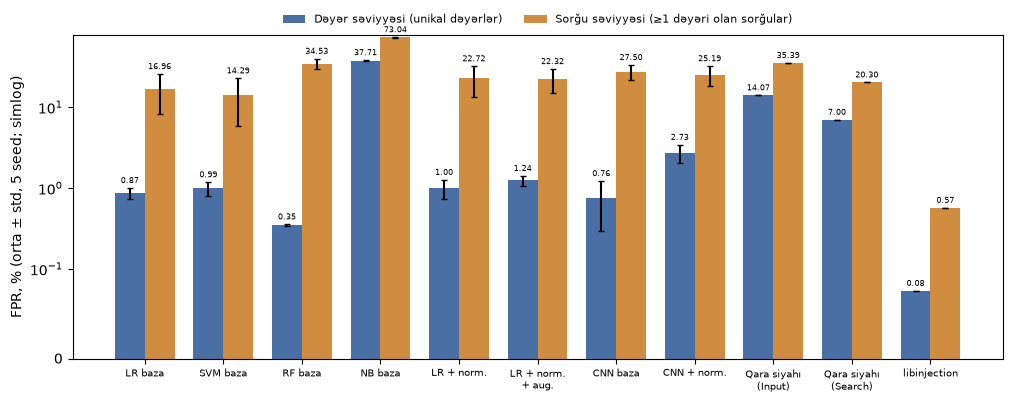

In [9]:
labels = [n.replace(" (sanitizeInput)", "\n(Input)").replace(" (sanitizeSearch)", "\n(Search)").replace("normallaşdırma", "norm.")
          .replace(" + augmentation", "\n+ aug.").replace("libinjection 4.0.1", "libinjection") for n in ORDER]
fig, ax = plt.subplots(figsize=(12, 4.2))
x, w = np.arange(len(ORDER)), 0.38
for i, (m, lab, col) in enumerate([("fpr_value_unique", "Dəyər səviyyəsi (unikal dəyərlər)", "#4a6fa5"),
                                    ("fpr_request", "Sorğu səviyyəsi (≥1 dəyəri olan sorğular)", "#d08c3f")]):
    d = a.xs(m, level="metric").loc[ORDER]
    b = ax.bar(x + (i - 0.5) * w, d["mean"], w, yerr=d["std"], capsize=2, color=col, label=lab)
    ax.bar_label(b, fmt="%.2f", fontsize=6, padding=2)
ax.set_yscale("symlog", linthresh=0.1)
ax.set_xticks(x, labels, fontsize=7)
ax.set_ylabel("FPR, % (orta ± std, 5 seed; simlog)")
ax.legend(fontsize=8, ncol=2, loc="lower center", bbox_to_anchor=(0.5, 1.0), frameon=False)
fig.savefig(FIG / "15_openappsec_fpr.png", dpi=300, bbox_inches="tight")
plt.show()